In [66]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import os
import json
import sys
import h5py
import pandas as pd
import xarray as xr
import ipywidgets as widgets
from datetime import timedelta
from pathlib import Path
from omnicloudmask import predict_from_array
from scipy.ndimage import gaussian_filter
from scipy.optimize import nnls
from scipy.ndimage import binary_erosion, binary_dilation
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from skimage.transform import downscale_local_mean
sys.path.append("/home/ucfacb0/ARIA/aria_data_analysis")
from load_data import load_data
from ast import literal_eval
from astropy.convolution import convolve, Gaussian2DKernel

from sentinelhub.data_collections import DataCollection
from sentinelhub.config import SHConfig
from sentinelhub.constants import MimeType
from sentinelhub.geo_utils import bbox_to_dimensions
from sentinelhub.api.process import SentinelHubRequest
from sentinelhub.constants import CRS
from sentinelhub.geometry import BBox

config = SHConfig()
config.sh_base_url = 'https://sh.dataspace.copernicus.eu'
config.sh_token_url = 'https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token'
# Error check to make sure credentials have been provided:
if not config.sh_client_id or not config.sh_client_secret:
    print("Warning! To use Process API, please provide the credentials (OAuth client ID and client secret).")

In [67]:
# Load data
platform = "sn"
site_name = "JQ_LC4394"
launch_ind = 4

if platform == "ls":
    clip = 0.3
    res = 30
else:
    clip = 5000
    res = 60

site_data = json.load(open(f"/home/ucfacb0/ARIA/aria_data_download/matches/matches_{platform}.json"))
launch_times = site_data[site_name]["launch_times"]
launch_time = pd.to_datetime(launch_times[launch_ind])
print(f"Processing launch {launch_ind+1}/{len(launch_times)} for site {site_name} at {res}m resolution.")

era5_data, xsc_mean, data_tar, data_ref = load_data(site_name, launch_ind, platform)

#ref_check_ind = 3
#raa = data_tar["raa"]
#data_tar = data_ref.isel(time=ref_check_ind).copy()
#data_ref = data_ref.drop_isel(time=ref_check_ind)
#data_tar["raa"] = raa

center_lat   = np.mean(data_tar["lat_range"].values)
center_lon   = np.mean(data_tar["lon_range"].values)
time_tar     = pd.Timestamp(data_tar["time"].values)
delta_t_secs = data_tar["delta_t_secs"].item()
time_tar    += pd.Timedelta(seconds=float(delta_t_secs))
time_ref     = data_ref["time"].values

Processing launch 5/5 for site JQ_LC4394 at 60m resolution.
Overpass is 5 mins after launch.
['2021-07-29T04' '2023-02-24T04' '2023-11-16T04' '2025-03-15T04'
 '2025-05-14T04'] ['2025-12-25T04:16:56.473000000' '2025-12-10T04:17:05.500000000'
 '2025-12-02T04:17:14.042000000' '2025-11-30T04:17:05.861000000'
 '2025-11-20T04:17:06.818000000' '2025-11-12T04:17:11.669000000'
 '2025-11-10T04:17:08.305000000' '2025-10-31T04:17:10.336000000'
 '2025-10-26T04:16:56.873000000' '2025-10-23T04:17:12.948000000'
 '2025-10-03T04:17:13.098000000' '2025-10-01T04:17:12.917000000'
 '2025-09-21T04:17:10.988000000' '2025-09-13T04:17:10.004000000'
 '2025-09-11T04:17:11.526000000' '2025-09-06T04:16:56.392000000'
 '2025-08-27T04:16:58.943000000' '2025-08-24T04:17:11.694000000'
 '2025-08-12T04:17:16.372000000' '2025-08-02T04:17:18.018000000'
 '2025-07-28T04:16:58.402000000' '2025-07-15T04:17:16.725000000'
 '2025-07-08T04:17:00.923000000' '2025-06-25T04:17:12.724000000'
 '2025-06-05T04:17:13.997000000' '2025-05-19

In [68]:
# Calculate the AMF.
sw_path = "/home/ucfacb0/ARIA/aria_data_analysis/data/AMFs_lookup_no2_440nm.he5"
with h5py.File(sw_path, "r") as f:
    dI0       = np.array(f["Scattering Weights/dI0"][:])      # type: ignore
    dI1       = np.array(f["Scattering Weights/dI1"][:])      # type: ignore
    dI2       = np.array(f["Scattering Weights/dI2"][:])      # type: ignore
    sza_grid  = np.array(f["Grid/SZA"][:])                    # type: ignore
    vza_grid  = np.array(f["Grid/VZA"][:])                    # type: ignore
    alb_grid  = np.array(f["Grid/Albedo"][:])                 # type: ignore   
    sp_grid   = np.array(f["Grid/Surface Pressure"][:])       # type: ignore
    alt_layer = np.array(f["Profiles/Altitude Layer"][:])     # type: ignore
    o3_labels = [s.decode() for s in f["Grid/OZO"][:]]        # type: ignore
    o3_col    = np.array(f["Profiles/Ozone Column Layer"][:]) # type: ignore

full_totals_DU = o3_col.sum(axis=0) / 2.69e16

target_lat = center_lat
if abs(target_lat) < 30:
    band = "L"
elif abs(target_lat) < 60:
    band = "M"
else:
    band = "H"
band_mask = np.array([label.startswith(band) for label in o3_labels])

# Determine the albedo for the target site.
with h5py.File("/home/ucfacb0/ARIA/aria_data_analysis/data/OMI-Aura_L3-OMLER_2005m01-2009m12_v003-2010m0503t063707.he5", "r") as f:
    base = "HDFEOS/GRIDS/EarthSurfaceReflectanceClimatology/Data Fields"
    wavelength   = np.array(f[f"{base}/Wavelength"][:]) # type: ignore
    ler          = np.array(f[f"{base}/MonthlySurfaceReflectance"][:]) # type: ignore
    lat_grid_ler = np.array(f[f"{base}/Latitude"][:]) # type: ignore
    lon_grid_ler = np.array(f[f"{base}/Longitude"][:]) # type: ignore

i_lat = np.argmin(np.abs(lat_grid_ler - center_lat))
i_lon = np.argmin(np.abs(lon_grid_ler - center_lon))
i_month = time_tar.month - 1  # 0-indexed
mask_wav = (wavelength >= 405) & (wavelength <= 465)
alb_val = np.mean(ler[i_month, mask_wav, i_lat, i_lon]) / 1000

def nearest_idx(grid, values):

    # Create two arrays of shape (1,1,n) and (nlat,nlon,1)
    # Subtract to get the residual between grid value and values value
    diff_grid = grid[np.newaxis, np.newaxis, :] - values[..., np.newaxis]

    # Take the absolute value and find the minimum index (closest).
    min_ind = np.argmin(np.abs(diff_grid), axis=-1)
    return min_ind

i_sza   = nearest_idx(sza_grid, data_tar["sza"].values)  # (nlat, nlon)
i_vza   = nearest_idx(vza_grid, data_tar["vza"].values)  # (nlat, nlon)
i_alb   = np.argmin(np.abs(alb_grid  - alb_val))
i_sp    = np.argmin(np.abs(sp_grid   - era5_data["sp"]))
i_z     = np.argmin(np.abs(alt_layer - era5_data["h_plume_km"])) # km
i_ozone = np.argmin(np.where(band_mask, np.abs(full_totals_DU - era5_data["ozone_DU"]), np.inf))
print(f"Ozone profile: {i_ozone} - {o3_labels[i_ozone]} ({full_totals_DU[i_ozone]:.1f} DU, ERA5: {era5_data['ozone_DU']:.1f} DU)")

# Index the dI arrays
dI0_slice = dI0[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
dI1_slice = dI1[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
dI2_slice = dI2[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
    
# Calculate AMF
# Gonzalo confirmed that SW values in the LUTs already account for the geometric AMF.
amf = dI0_slice + dI1_slice * np.cos(np.radians(data_tar["raa"].values)) + dI2_slice * np.cos(2 * np.radians(data_tar["raa"].values))

Ozone profile: 5 - M250 (310.5 DU, ERA5: 333.6 DU)


In [69]:
def create_rgb(data,clip):
    rgb = np.stack([
        data["B04"],
        data["B03"],
        data["B02"],
    ], axis=-1)
    return np.clip(rgb / clip, 0, 1)

def compute_water_mask(data, filters, scene_ind=None):

    '''This uses the band data to detect water and snow/salinity, 
    and remove the brightest pixels.'''
    
    band1 = data["B03"].values.astype(np.float32)
    band2 = data["B08"].values.astype(np.float32) if platform == "sn" else data["B05"].values.astype(np.float32)
    band3 = data["B11"].values.astype(np.float32) if platform == "sn" else data["B06"].values.astype(np.float32)
    b02 = data["B02"].values.astype(np.float32)
    b03 = data["B03"].values.astype(np.float32)
    b04 = data["B04"].values.astype(np.float32)

    # --- handle optional time dimension ---
    if scene_ind is not None:
        band1 = band1[scene_ind]
        band2 = band2[scene_ind]
        band3 = band3[scene_ind]

        b02 = b02[scene_ind]
        b03 = b03[scene_ind]
        b04 = b04[scene_ind]
            
    # Calculate the water and snow/salinity mask
    ndwi = (band1 - band2) / (band1 + band2 + 1e-10)
    ndsi = (band1 - band3) / (band1 + band3 + 1e-10)
    water_mask = (ndwi > filters[1]) | (ndsi > filters[2])

    # Calculate the brightness mask
    brightness = np.nanmean(np.stack([b02,b03,b04]),axis=0)
    struct = np.ones((2 * filters[3] + 1, 2 * filters[3] + 1))
    if brightness.ndim == 2:
        threshold = np.nanpercentile(brightness, filters[0])
        bright_mask = brightness > threshold
        mask = water_mask | bright_mask
        masks = binary_dilation(mask, structure=struct)
    else:
        thresholds = np.nanpercentile(brightness,filters[0],axis=(1, 2))
        bright_mask = brightness > thresholds[:, None, None]
        masks = water_mask | bright_mask
        
        masks = np.array([binary_dilation(m, structure=struct) for m in masks])
        
    return masks.astype(bool)

def compute_validland_mask(crop, filters, ind_ref=None):

    shape = data_tar["B01"].shape
    if ind_ref is None:
        ref_idx = np.arange(data_ref["B01"].shape[0])
    else:
        ref_idx = ind_ref
    
    # Water mask
    water_mask_tar  = compute_water_mask(data_tar, filters)
    water_mask_refs = compute_water_mask(data_ref, filters, ref_idx)
    water_mask = water_mask_tar | np.any(water_mask_refs, axis=0)
    
    # Valid mask
    if platform == "sn":
        valid_mask = data_tar["dataMask"].values.astype(bool) & np.all(data_ref["dataMask"].values[ref_idx, ...].astype(bool), axis=0)
    elif platform == "ls":
        valid_mask = np.isfinite(data_tar["B01"].values) & np.any(np.isfinite(data_ref["B01"].isel(time=ref_idx).values), axis=0)
    
    total_px = shape[0]*shape[1]
    valid_frac = np.sum(valid_mask) / total_px * 100
    print(f"{valid_frac:.2f}% Valid Pixels")

    valid_mask = valid_mask & compute_center_mask(crop, data_tar["B01"])
    
    return valid_mask, water_mask

def compute_center_mask(crop,data):

    # Center mask
    h_min_frac, h_max_frac, w_min_frac, w_max_frac = crop
    height, width = data.shape
    h_start = int(h_min_frac * height)
    h_end   = int(h_max_frac * height)
    w_start = int(w_min_frac * width)
    w_end   = int(w_max_frac * width)
    center_mask = np.zeros_like(data, dtype=bool)
    center_mask[h_start:h_end, w_start:w_end] = True

    return center_mask

def compute_clusters(data_tar, validland_mask, n_clusters):

    # Add some extra features to help the clustering - NDVI, NDWI, NDSI.
    if platform == "sn":
        band2 = data_tar["B08"]
        NDSI = ((data_tar["B03"] - data_tar["B11"]) / (data_tar["B03"] + data_tar["B11"] + 1e-6)).values

    elif platform == "ls":
        band2 = data_tar["B05"]
        NDSI = ((data_tar["B03"] - data_tar["B06"]) / (data_tar["B03"] + data_tar["B06"] + 1e-6)).values

    NDVI = ((band2 - data_tar["B04"]) / (band2 + data_tar["B04"] + 1e-6)).values
    NDWI = ((data_tar["B03"] - band2) / (data_tar["B03"] + band2 + 1e-6)).values

    band_vars = [v for v in data_tar.data_vars if v.startswith("B") and v != "B01"]
    bands = np.stack([data_tar[v].values for v in band_vars], axis=-1)  # (H, W, nB)
    features = np.concatenate([bands, NDVI[..., None], NDWI[..., None], NDSI[..., None]],axis=-1)

    # Apply a gaussian smoothing kernel to help with the clustering, only smoothing over pixels not bands.
    features = gaussian_filter(features, sigma=(1,1,0))
    
    """K-means clustering on RxCxB hyperspectral image. Returns RxC class map."""
    R, C, B = features.shape
    pixels = features.reshape(-1, B)
    land_mask = validland_mask.reshape(-1)
    mask = np.all(np.isfinite(pixels), axis=1) & land_mask
    X = pixels[mask]
    labels = np.full(R * C, -1, dtype=np.int32)

    # Keep the PCA components that explain 99% of the variance.
    pca = PCA(n_components=0.99)
    pix_reduced = pca.fit_transform(X)
    print(f"PCs for 99% variance: {pca.n_components_}.")

    labels[mask] = MiniBatchKMeans(n_clusters=n_clusters, batch_size=1024, n_init=3, random_state=0).fit_predict(pix_reduced)
    clusters = labels.reshape(R, C)

    unique, counts = np.unique(labels[mask], return_counts=True)
    pixel_counts = dict(zip(unique, counts))

    max_count = max(pixel_counts.values())
    bar_width = 75  # Max width of bars in characters
    #print("Pixels per cluster:")
    ## Print a bar to the terminal for each cluster for a visual check.
    #for cluster, count in pixel_counts.items():
    #    bar_len = int((count / max_count) * bar_width)
    #    bar = "█" * bar_len
    #    print(f"Cluster {cluster}: {count:>8} | {bar}")
    
    return clusters


In [70]:
def plot_watermask(brightness_filter, NDWI_filter, NDSI_filter, crop_x, crop_y):
    
    crop1, crop2 = crop_x
    crop3, crop4 = crop_y
    crop = (crop1, crop2, crop3, crop4)
    print(crop)
    shape = data_tar["B01"].shape
    filters = [brightness_filter, NDWI_filter, NDSI_filter, 0]
    water_mask_tar = compute_water_mask(data_tar, filters, None)
    
    if platform == "sn":
        data_mask_union = data_tar["dataMask"].values.astype(bool)
    elif platform == "ls":
        data_mask_union = np.isfinite(data_tar["B01"].values)
        
    validland_mask = data_mask_union & (~water_mask_tar)

    total_px = shape[0]*shape[1]
    valid_frac = np.sum(validland_mask) / total_px * 100
    print(f"{valid_frac:.2f}% Valid Pixels")
    
    # Crop
    center_mask = compute_center_mask(crop, data_tar["B01"])
    validland_mask = validland_mask & center_mask

    fig, ax = plt.subplots(1,2,figsize = (10,5)) 
    rgb = create_rgb(data_tar,clip)
    rgb_masked = rgb.copy()
    rgb_masked[~center_mask] = 1.0 
    ax[0].imshow(rgb_masked)
    ax[1].imshow(np.where(validland_mask, 1, 0), cmap='gray', vmin=0, vmax=1)
    for i in range(2):
        ax[i].set_aspect("equal")  
        ax[i].set_xticks([])
        ax[i].set_yticks([])
    fig.tight_layout()

widgets.interact(plot_watermask,
                 brightness_filter = (80.0,100.0,0.1),
                 NDWI_filter=(0,1,0.1),
                 NDSI_filter=(0,1,0.1),
                 crop_y=widgets.FloatRangeSlider(min=0, max=1, step=0.05, value=[0.0, 1.0], description='x range'),
                 crop_x=widgets.FloatRangeSlider(min=0, max=1, step=0.05, value=[0.0, 1.0], description='y range'));

interactive(children=(FloatSlider(value=90.0, description='brightness_filter', min=80.0), FloatSlider(value=0.…

In [71]:
def find_refs(mask, number_refs):
    ''' Loops through all cloud-free scenes for the same year and selects the scenes most consistent with the target overpass.

    Only look over land pixels, and find references with a similar B04 band using RMSE.
    For sza and vza, use a absolute degree difference.'''       

    # Define the scenes. The launch scenes are already removed from the references when the data is loaded. 

    b04_tar  = data_tar["B04"].values[mask] # Valid land pixels only.
    b04_refs = data_ref["B04"].values[:,mask] # Valid land pixels only.

    # Normalize so that a scene that's spectrally identical but globally darker now scores ~0.
    tar_norm  = b04_tar / b04_tar.mean()
    refs_norm = b04_refs / b04_refs.mean(axis=1, keepdims=True)
    rmse_br_all = np.sqrt(np.mean((tar_norm - refs_norm) ** 2, axis=1))
    data_len = data_ref["sza"].shape[0]

    tar_mean = data_tar["vza"].mean(skipna=True).item()
    ref_means = data_ref["vza"].mean(dim=["y","x"], skipna=True).values
    vza_diff_all = np.abs(tar_mean - ref_means)
    vza_diff_all = np.array(vza_diff_all)

    # Hard threshold for vza. 
    # The viewing angle difference is typically close to zero or around 3 degrees.
    vza_thresh = 2.0
    valid_idx = np.where(vza_diff_all < vza_thresh)[0]
    if len(valid_idx) == 0:
        ind_ref = []
    else:

        # Now find the best references of whats left.
        rmse_valid = rmse_br_all[valid_idx]
        best_local = np.argsort(rmse_valid)[:number_refs]
        ind_ref = valid_idx[best_local]
            
    # Quick check on reference locations:
    print('Ref indices: ', ind_ref, time_ref[ind_ref])
    print(f"VZA Filter: {np.sum(vza_diff_all < vza_thresh)}/{data_len}")

    return ind_ref

In [72]:
def initial_plots(mask, mf_clusters, n_clusters, crop):
    ###################################################
    # Plot the target, validland mask and the clusters.
    ###################################################
    fig, ax = plt.subplots(1,2,figsize = (10, 5)) 
    rgb = create_rgb(data_tar,clip)
    ax[0].imshow(rgb)
    H, W = rgb.shape[:2]
    ax[0].plot(W/2, H/2, marker='*', color='yellow', markersize=20,markeredgecolor='black', markeredgewidth=0.8, zorder=10)
    ax[0].set_title('Target')

    # Create red overlay (RGBA)
    overlay = np.zeros((*mask.shape, 4))  # 4 = RGBA
    overlay[..., 0] = 1.0          # Red channel
    overlay[..., 3] = mask * 0.4  # Alpha (transparency)

    # Plot overlay
    ax[0].imshow(overlay)
    
    cluster_plot = np.ma.masked_where(mf_clusters == -1, mf_clusters)
    ax[1].imshow(cluster_plot, cmap=plt.colormaps['gist_rainbow'].resampled(n_clusters), interpolation='nearest')
    ax[1].set_title(f'K-means ({mf_clusters.max()+1} clusters)')

    for i in range(2):
        ax[i].set_aspect("equal")  
        ax[i].set_xticks([])
        ax[i].set_yticks([])

    h_min, h_max, w_min, w_max = crop
    H, W = rgb.shape[:2]

    # 1 outside the crop region, 0 inside — this is what gets hatched
    outside = np.ones((H, W), dtype=float)
    outside[int(h_min*H):int(h_max*H), int(w_min*W):int(w_max*W)] = 0

    x0 = w_min * W
    y0 = h_min * H
    width = (w_max - w_min) * W
    height = (h_max - h_min) * H

    for a in ax:
        rect = Rectangle(
            (x0, y0),
            width,
            height,
            fill=False,
            edgecolor='cyan',
            linewidth=2
        )
        a.add_patch(rect)
    
    fig.tight_layout()

def plot_refs(ind_ref, valid_mask, water_mask):
        
    fig, ax = plt.subplots(1,len(ind_ref),figsize = (len(ind_ref)*5,5)) 
    for i in range(len(ind_ref)):
        rgb = create_rgb(data_ref.isel(time=ind_ref[i]),clip)
        rgb_masked = rgb.copy()

        mask = ~valid_mask | water_mask

        overlay = np.zeros((*mask.shape, 4))  # 4 = RGBA
        overlay[..., 0] = 1.0          # Red channel
        overlay[..., 3] = mask * 0.4  # Alpha (transparency)        

        #rgb_masked[~valid_mask] = 1.0 
        if len(ind_ref) > 1:
            ax[i].imshow(rgb_masked)
            ax[i].imshow(overlay)
            ax[i].set_title(f"Ref {i}")
            ax[i].set_aspect("equal")  
            ax[i].set_xticks([])
            ax[i].set_yticks([])
        else:
            ax.imshow(rgb_masked)
            ax.imshow(overlay)
            ax.set_title(f"Ref {i}")
            ax.set_aspect("equal")  
            ax.set_xticks([])
            ax.set_yticks([])
    if len(ind_ref) == 0:
        raise ValueError("No references found.")
    fig.tight_layout()

def scatter_ratio_plot(ref_flat, target_flat, c, ratio, retrieval):

    fig, ax = plt.subplots(1,2,figsize=(8,4),layout="constrained")

    ax[0].scatter(ref_flat, target_flat, s=5, alpha=0.5)
    x = np.linspace(ref_flat.min(), ref_flat.max(), 100)
    ax[0].plot(x, c * x, label=f'Best fit: y={c:.6f}x')
    ax[0].plot(x, x, linestyle='--', label='1:1 line')
    ax[0].set_xlabel("Reflectance (Target-weighted Reference)")
    ax[0].set_ylabel("Reflectance (Target)")
    ax[0].legend()
    ax[0].grid(True)
    if retrieval == 1:
        ax[0].set_title("Reflectance Comparison over Valid Land Pixels")
    else:
        ax[0].set_title("Reflectance Comparison over Valid Land Non-Plume Pixels")

    # Plot the ratio of the target to reference scene.
    im = ax[1].imshow(ratio, cmap='RdBu_r', vmin=0.9, vmax=1.1)
    H, W = ratio.shape[:2]
    ax[1].quiver(W/2, H/2, era5_data["u100"].item(), -era5_data["v100"].item(), color='black', scale=0.1, angles='xy', scale_units='xy') 
    ax[1].set_title(f'{site_name} - {time_tar:%H:%M:%S}',)
    plt.colorbar(im, ax=ax[1],fraction=0.046, pad=0.04, label = "Ratio = c * target / reference")
    ax[1].set_xticks([])
    ax[1].set_yticks([])

def plot_final_image(no2_vcd, source_rate, crop, vmax):

    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))

    # Set up background image
    rgb = create_rgb(data_tar, clip)

    # Convert fractional bounds to pixel indices
    h_min_frac, h_max_frac, w_min_frac, w_max_frac = crop
    h, w = rgb.shape[:2]
    y_start = int(h_min_frac * h)
    y_end   = int(h_max_frac * h)
    x_start = int(w_min_frac * w)
    x_end   = int(w_max_frac * w)

    cy = h/2 - y_start
    cx = w/2 - x_start


    fig.suptitle(f'{site_name} - {time_tar} - {source_rate:.0f} kg',fontweight='normal')
    for i in range(2):
        for j in range(2):
            
            ax[i,j].imshow(rgb[y_start:y_end, x_start:x_end])
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])
            ax[i,j].plot(cx, cy, marker='*', color='yellow', markersize=10,
               markeredgecolor='black', markeredgewidth=0.8, zorder=10)
            
            # Print over land only, and set vmin to 0.
            no2_crop = no2_vcd[j][i][y_start:y_end, x_start:x_end]
            im = ax[i,j].imshow(no2_crop, cmap='magma', vmin=0, vmax=vmax)
            cbar = fig.colorbar(im, ax=ax[i,j], fraction=0.039, pad=0.04)
            cbar.set_label('NO$_2$ column enhancement (mol m$^{-2}$)')

    # Plot scalebar
    pixel_size_m = 30 if platform == "ls" else 60
    length_m = 750
    bar_px = length_m / pixel_size_m
    crop_h = y_end - y_start
    crop_w = x_end - x_start
    bar_height_px = crop_h * 0.02
    x0 = crop_w * 0.80          # right side, in pixel units of the cropped image
    y0 = crop_h * 0.92          # near the bottom (imshow origin is upper)
    
    pad_x = bar_px * 0.25
    bg = Rectangle((x0 - pad_x, y0 - bar_height_px * 4.5),
                   bar_px + 2 * pad_x, bar_height_px * 6.5,
                   facecolor="black", alpha=0.35, zorder=18)
    ax[1, 1].add_patch(bg)

    # Draw rectangle
    rect = Rectangle((x0, y0), bar_px, bar_height_px,
                    facecolor="white", edgecolor='black', lw=1.5, zorder=20)
    ax[1,1].add_patch(rect)

    # Label
    ax[1,1].text(x0 + bar_px / 2, y0 - bar_height_px * 0.5,
            f"{int(length_m)} m", color='white',
            ha='center', va='bottom',
            fontsize=12, fontweight='bold', zorder=20) 

    ax[0,0].set_title("First retrieval (no plume mask)")
    ax[0,1].set_title("Second retrieval (with plume mask)")
        
    fig.tight_layout()
    if not os.path.exists(f"out/{site_name.replace('/', '')}"):
        os.makedirs(f"out/{site_name.replace('/', '')}")

In [73]:
def compute_cloudmask(ind_ref, platform):

    cld_dir = "/home/ucfacb0/ARIA/aria_data_analysis/data/cld"
    times = [time_tar]
    for ind in ind_ref:
        times.append(pd.Timestamp(time_ref[ind]))
    union = None
    for time in times:
        filename = os.path.join(cld_dir, f"cld_{site_name}_{time.strftime('%Y%m%d_%H%M')}.nc")
        if platform == "sn":
            if not os.path.exists(filename):

                with xr.open_dataset(f"/home/ucfacb0/ARIA/aria_data_download/download/{site_name}/sentinel-2-l1c-band-l2a-slc-{site_name}-60-tar.nc") as ds:
                    crs = ds.attrs["crs"]

                time_start = (time-timedelta(hours=0.5)).strftime("%Y-%m-%dT%H:%M:%SZ")
                time_end   = (time+timedelta(hours=0.5)).strftime("%Y-%m-%dT%H:%M:%SZ")
                bbox = BBox([center_lon - 0.08, center_lat - 0.06,
                            center_lon + 0.08, center_lat + 0.06], crs=CRS.WGS84)
                bbox_utm = bbox.transform(CRS(crs))

                request_res_dep_data = SentinelHubRequest(
                    data_folder='download', evalscript=Path(f"/home/ucfacb0/ARIA/aria_data_download/evalscripts/evalscript_10m.js").read_text(),
                    input_data=[SentinelHubRequest.input_data(
                                data_collection=DataCollection.SENTINEL2_L1C.define_from("s2l1c", service_url=config.sh_base_url),
                                time_interval=(time_start, time_end),
                                other_args={"id":"S2L1C"})],
                    responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
                    bbox=bbox_utm, size=bbox_to_dimensions(bbox_utm, resolution=10), config=config,
                )   

                requested_data_10 = request_res_dep_data.get_data()[0]
                shape = np.shape(requested_data_10)

                # Convert the data_out dict into xarray Variables with appropriate dimensions and attributes.
                data_vars = {}
                for ind, var in enumerate(["B02", "B03", "B04", "B08"]):
                    data_vars[var] = xr.Variable(
                        dims=("y", "x"),
                        data=requested_data_10[..., ind],
                        attrs={"long_name": 'Sentinel-2-l1c TOA reflectance', "units": "DN"}
                    )

                # --- Construct Dataset ---
                ds_10m = xr.Dataset(
                    data_vars=data_vars,
                    coords={
                        "x":         ("x",         np.arange(shape[1], dtype=np.int32), {"long_name": "pixel col index", "units": "1"}),
                        "y":         ("y",         np.arange(shape[0], dtype=np.int32), {"long_name": "pixel row index", "units": "1"}),
                    },
                    attrs={"Data_Attribution": f"Sentinel-2 data for Site: {site_name}",
                            "crs": crs})
                
                ds_10m.to_netcdf(filename)

            ds_10m = xr.open_dataset(filename)

            input_array = np.stack([
                ds_10m["B04"],   # Red
                ds_10m["B03"],   # Green
                ds_10m["B08"],   # NIR
            ]).astype(np.float32)
        
        elif platform == "ls":
            
            input_array = np.stack([
                data_tar["B04"],   # Red
                data_tar["B03"],   # Green
                data_tar["B05"],   # NIR
            ]).astype(np.float32)
            nodata_px = ~np.isfinite(input_array).all(axis=0)  # catches both inf and nan
            input_array = np.where(np.isfinite(input_array), input_array, 0.0).astype(np.float32)
        
        cloud_mask = predict_from_array(input_array)[0] > 0
        union = cloud_mask if union is None else (union | cloud_mask)
    
    return union

100.00% Valid Pixels
Ref indices:  [25 28] ['2025-05-19T04:16:58.111000000' '2025-04-24T04:17:19.342000000']
VZA Filter: 40/40
100.00% Valid Pixels
PCs for 99% variance: 3.


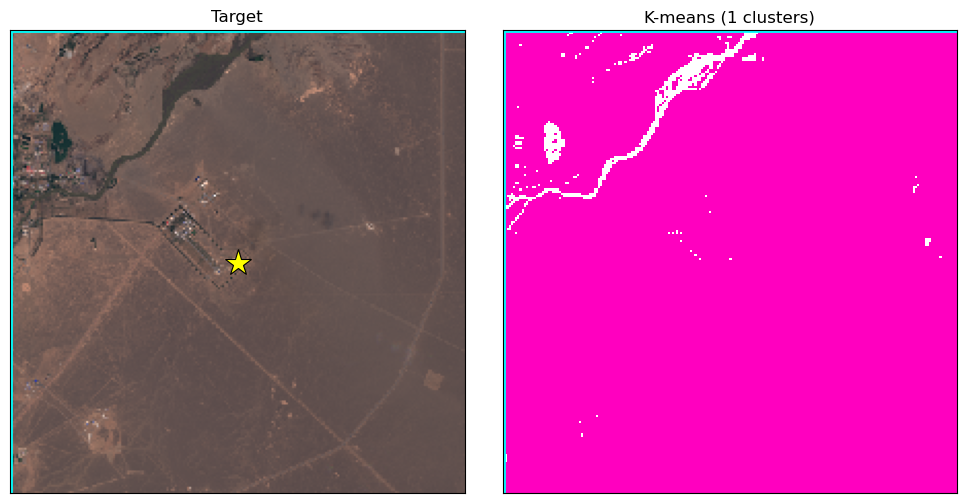

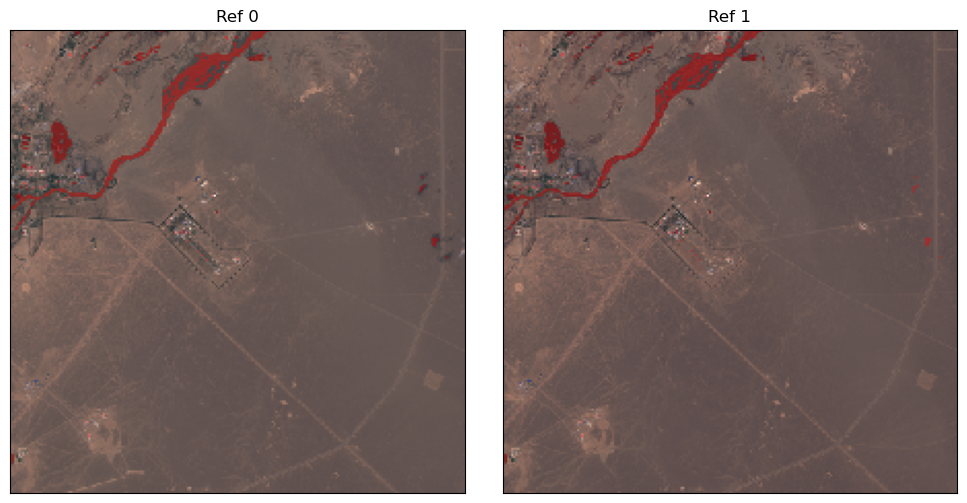

In [74]:
#############
# Parameters:
#############

#   - crop range
#   - number refs
#   - number clusters
#   - sigma x 2
#   - percentile x 2
#   - morph structure size
#   - morph iterations

crop = (0.0,0.8,0.2,0.75)
crop = (0,1,0,1) 
center_mask = compute_center_mask(crop, data_tar["B01"]) 
filters = [100, 0, 0, 0]

number_refs = 2
n_clusters = 1

# Calculate the valid, crop, and water masks across all refs and target
valid_mask, water_mask = compute_validland_mask(crop, filters)

# Now find refs with the most similar RMSE (over all valid land pixels)
ind_ref = find_refs(valid_mask&~water_mask, number_refs=number_refs)

# Now recreate the mask over the target and refs only
valid_mask, water_mask = compute_validland_mask(crop, filters, ind_ref)

# Calculate the cloud mask (for the targets and chosen refs only, as this takes a while)
cloud_mask = False
if cloud_mask:
    cloud_mask = compute_cloudmask(ind_ref, platform) # use omnicloudmask
    if platform == "sn":
        shape = np.shape(valid_mask)
        frac = downscale_local_mean(cloud_mask.astype(float), (6, 6))
        cloud_frac  = frac[:shape[0], :shape[1]]
        cloud_mask = cloud_frac > 0
        valid_mask = valid_mask & (~cloud_mask)
    elif platform == "ls":
        valid_mask = valid_mask & ~cloud_mask

# Split the target into clusters over all valid, non-water, non-cloud pixels.
mf_clusters = compute_clusters(data_tar, valid_mask&~water_mask, n_clusters)

# Plot.
initial_plots(~valid_mask&water_mask, mf_clusters, n_clusters, crop)
plot_refs(ind_ref, valid_mask, water_mask)

In [75]:
def build_clustered_ref(refs, target, background_mask, mf_clusters, n_clusters,
                        min_pixels=50, fallback_w=None):
    """
    Solve a separate NNLS fit per k-means cluster and assemble a single
    reference scene where each pixel uses its own cluster's weights.

    refs            : (N_refs, H, W)
    target          : (H, W)
    background_mask : (H, W) bool — valid land, non-plume pixels to fit on
    mf_clusters     : (H, W) int  — cluster labels, -1 = unassigned
    """
    H, W = target.shape
    N = refs.shape[0]
    ref = np.zeros((H, W), dtype=float)
    weights_per_cluster = {}

    # Global fallback fit (used for clusters with too few background pixels)
    if fallback_w is None:
        m = background_mask
        fallback_w, _ = nnls(refs[:, m].T, target[m])

    for k in range(n_clusters):
        cluster_mask = (mf_clusters == k)
        fit_mask = cluster_mask & background_mask    # fit only on good pixels
        n_fit = int(np.sum(fit_mask))

        if n_fit >= min_pixels:
            w_k, _ = nnls(refs[:, fit_mask].T, target[fit_mask])
        else:
            w_k = fallback_w
            print(f"Cluster {k}: only {n_fit} background px — using global fallback.")
        weights_per_cluster[k] = w_k

        # Apply this cluster's weights to ALL pixels in the cluster
        # (including plume pixels, which we still need a reference for).
        ref_k = sum(w_k[i] * refs[i] for i in range(N))
        ref[cluster_mask] = ref_k[cluster_mask]

    # Pixels with no cluster label (-1): fill with the global fallback fit.
    unassigned = (mf_clusters == -1)
    if np.any(unassigned):
        ref_fb = sum(fallback_w[i] * refs[i] for i in range(N))
        ref[unassigned] = ref_fb[unassigned]

    print("Per-cluster reference weightings:")
    for k, w_k in weights_per_cluster.items():
        print(f"  Cluster {k}: {np.round(w_k, 4)}")

    return ref, weights_per_cluster

def calc_retrieval(target, ref, valid_mask, water_mask, plume_mask):

    # If theres a plume mask, create a non-plume, valid land pixel mask.
    mask = valid_mask & ~water_mask
    if plume_mask is not None:
        retrieval = 2
        mask = mask & ~plume_mask
    else:
        retrieval = 1

    # Flatten everything so its one line of pixels and calculate the scale factor (2D array).
    # The ratio should always be calculated over valid, non-water, non-cloud pixels.
    flattened_mask = mask.flatten()
    ref_flat    = ref.flatten()[flattened_mask]
    target_flat = target.flatten()[flattened_mask]
    c = (ref_flat @ target_flat) / (ref_flat @ ref_flat)
    
    # Equation 1 - Normalized Reflectance Ratio
    # Valid pixels only, exclude water, exclude cloud.
    ratio = np.full_like(target, np.nan)
    ratio[valid_mask & ~water_mask] = c * target[valid_mask & ~water_mask] / ref[valid_mask & ~water_mask]

    # Equation 2 - NO2 slant column enhancements  [mol m-2]
    no2_scd = (-1) * np.log(ratio) / xsc_mean

    # Equation 3 - Vertical columns  [mmol m-2]
    no2_vcd = (no2_scd / amf)
    
    # Check how similar the target and reference are in the background (non-plume) pixels.
    valid = np.isfinite(ratio)
    q = np.nanpercentile(ratio[mask & valid]* 100, [5, 95])
    print(f"5-95 ratio percentile: {q[1]-q[0]:.2f}%")
    bg = ratio[mask & valid]
    bg_err = np.nanstd(bg) * 100
    print(f"1σ background ratio dispersion: {bg_err:.2f}%")

    # Save an image showing some diagnostics.
    scatter_ratio_plot(ref_flat, target_flat, c, ratio, retrieval)
    return no2_vcd

def isolate_plume(no2_vcd, sigma, percentile):
    # Smooth using astropy to handle NaNs.
    kernel = Gaussian2DKernel(x_stddev=sigma)
    no2_smooth = convolve(no2_vcd, kernel, nan_treatment="interpolate", preserve_nan=True)
    threshold  = np.nanpercentile(no2_smooth, percentile)
    plume_mask = (no2_smooth > threshold)
    display_mask = plume_mask & valid_mask
    no2_plume = np.ma.masked_where(~display_mask, no2_vcd)

    return no2_smooth, no2_plume, plume_mask

def tweak_morphology(sigma,percentile,morph_struct_size, morph_iterations):

    no2_smooth, no2_plume, plume_mask = isolate_plume(no2_vcd, sigma, percentile)

    # Alternating erosion/dilation of the plume mask to remove artifacts (2nd retrieval only)
    struct = np.ones((morph_struct_size, morph_struct_size))
    for i in range(morph_iterations):
        plume_mask = binary_dilation(binary_erosion(plume_mask, struct), struct)
        plume_mask = binary_erosion(binary_dilation(plume_mask, struct), struct)
    display_mask = plume_mask & valid_mask
    no2_final = np.ma.masked_where(~display_mask, no2_vcd)

    fig, ax = plt.subplots(1,4, figsize=(20, 5))
    rgb = create_rgb(data_tar, clip)
    # Convert fractional bounds to pixel indices
    h_min_frac, h_max_frac, w_min_frac, w_max_frac = crop
    h, w = rgb.shape[:2]
    y_start = int(h_min_frac * h)
    y_end   = int(h_max_frac * h)
    x_start = int(w_min_frac * w)
    x_end   = int(w_max_frac * w)
    cy = h/2 - y_start
    cx = w/2 - x_start
    plot_arrays = [no2_vcd,no2_smooth,no2_plume,no2_final]
    plot_titles = ["VCD","VCD Smoothed","Isolated Plume","Artifacts Removed"]
    for i in range(4):
        ax[i].imshow(rgb[y_start:y_end, x_start:x_end])
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].plot(cx, cy, marker='*', color='yellow', markersize=10,
               markeredgecolor='black', markeredgewidth=0.8, zorder=10)
        max_range = np.nanmax(np.abs(no2_smooth[center_mask]))
        print(max_range)
        ax[i].imshow(plot_arrays[i][y_start:y_end, x_start:x_end], vmin=-max_range, vmax=max_range, cmap='magma')
        ax[i].set_title(plot_titles[i])
    fig.tight_layout()

Per-cluster reference weightings:
  Cluster 0: [0.6326 0.3298]
5-95 ratio percentile: 3.77%
1σ background ratio dispersion: 1.55%
Per-cluster reference weightings:
  Cluster 0: [0.616  0.3509]
5-95 ratio percentile: 3.00%
1σ background ratio dispersion: 1.32%


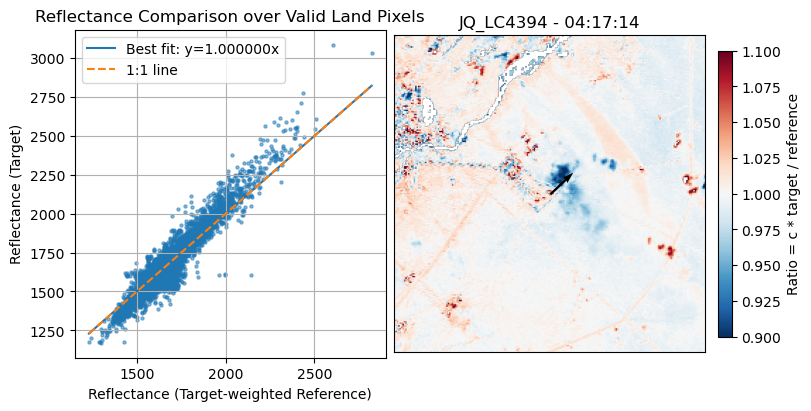

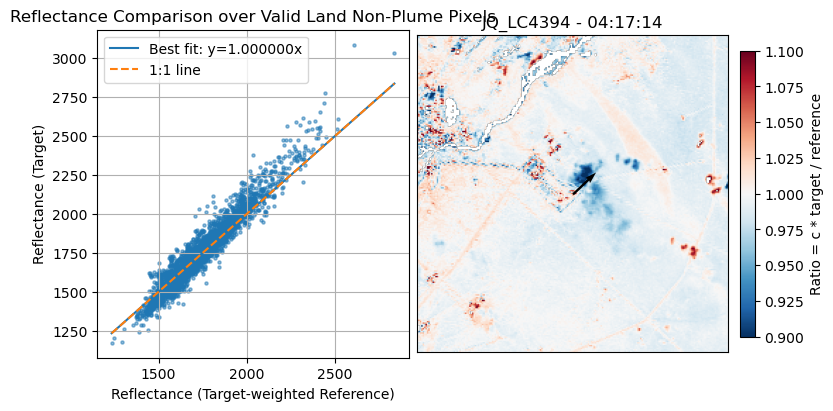

interactive(children=(FloatSlider(value=2.0, description='sigma', max=3.0, min=1.0), IntSlider(value=87, descr…

In [76]:
sigma = 3
percentile = 75
morph_struct_size = 5

target_band = "B01"
target = data_tar[target_band].values                    #         (H, W) - target scene
refs   = data_ref[target_band].isel(time=ind_ref).values # (N_refs, H, W) - reference scenes

###############
# Retrieval 1
###############

# Calculate the weighted references with over non-plume, valid, non-water, non-cloud pixels.
ref, weights_per_cluster = build_clustered_ref(refs, target, valid_mask&~water_mask, mf_clusters, n_clusters)

no2_plume_list = []
# First retrieval to get the plume mask.
no2_vcd = calc_retrieval(target,
                         ref,
                         valid_mask,
                         water_mask,
                         None)


no2_smooth, no2_plume, plume_mask = isolate_plume(no2_vcd, 3, 75)

do_retrieval_2 = True
if do_retrieval_2:

    ###############
    # Retrieval 2
    ###############

    # Calculate the linear weighted references with over non-plume valid land pixels.
    background_mask = valid_mask &~water_mask & ~plume_mask
    ref, weights_per_cluster = build_clustered_ref(refs, target, background_mask, mf_clusters, n_clusters)

    # Second retrieval to get the final plume.
    no2_vcd = calc_retrieval(target,
                             ref, 
                             valid_mask,
                             water_mask,
                             plume_mask)

    widgets.interact(tweak_morphology, sigma = (1,3,0.1), percentile=(75,100,1), morph_struct_size=(1,10,1), morph_iterations=(1,10,1))

    no2_smooth, _, plume_mask = isolate_plume(no2_vcd, 3, 95)
    no2_plume_list.append((no2_vcd,no2_plume))

    struct = np.ones((morph_struct_size, morph_struct_size))
    for i in range(2):
        plume_mask = binary_dilation(binary_erosion(plume_mask, struct), struct) # remove artifacts
        plume_mask = binary_erosion(binary_dilation(plume_mask, struct), struct) # close holes

    display_mask = plume_mask & valid_mask
    no2_plume = np.ma.masked_where(~display_mask, no2_vcd)
    no2_plume_list.append((no2_vcd,no2_plume))

SNR is 2.44329571723938.


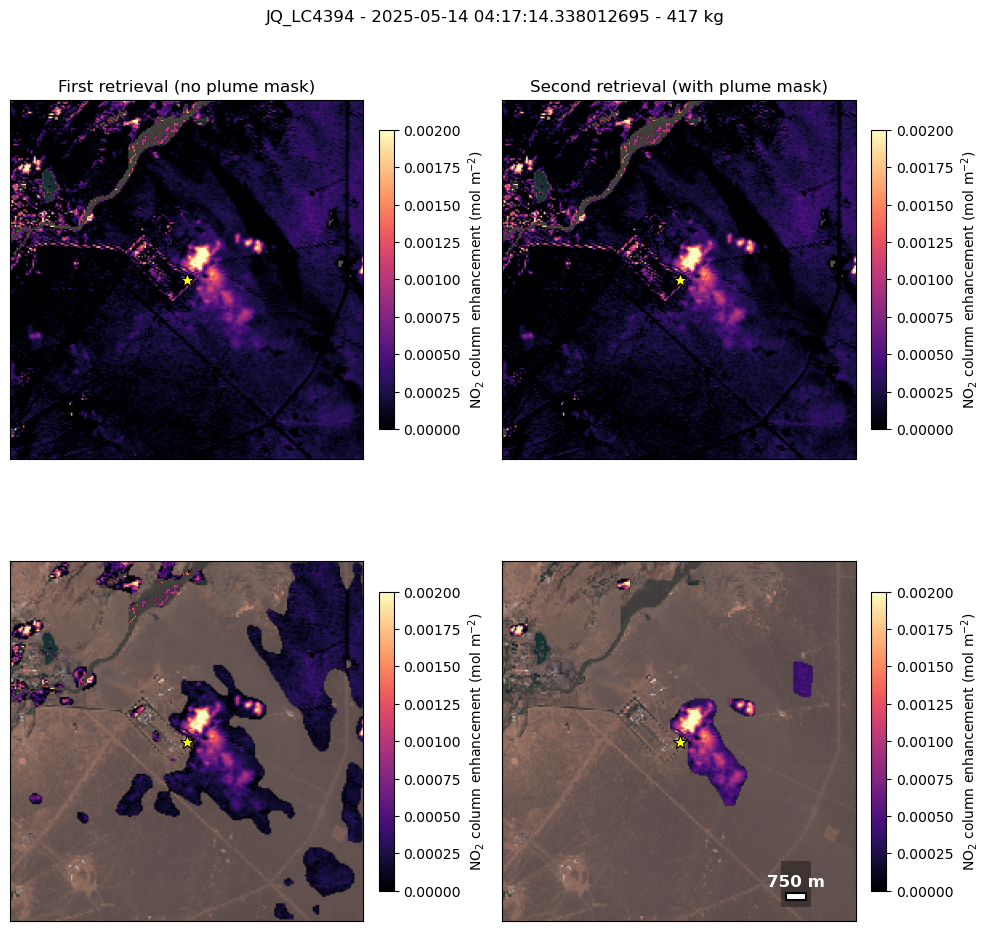

In [77]:
# Final SNR check
sigma_noise = np.nanstd(no2_vcd[background_mask & np.isfinite(no2_vcd)])
mu_plume    = np.nanmean(no2_vcd[plume_mask & np.isfinite(no2_vcd)])
snr = mu_plume / sigma_noise
print(f"SNR is {snr}.")

#######################
# Emission Calculation
#######################

mw_no2 = 0.04601  # kg/mol
pixel_area = res ** 2 # m2
L_eff = 1.74
tau = 2 * 60 * 60
ime_no2 = np.nansum(no2_plume * pixel_area)  # mol of NO2 (sum over plume pixels)
factor = np.exp(delta_t_secs / tau) if delta_t_secs >= (20 * 60) else 1.0
ime_nox = factor * mw_no2 * ime_no2 * L_eff  # kg of NOx
plot_final_image(no2_plume_list, ime_nox, crop, 0.002)

In [78]:
#############
# Parameters
#############

#file_params = pd.read_excel("/home/ucfacb0/ARIA/aria_data_analysis/retrievals.xlsx", header=None).set_index(0).T.set_index("Scene")
#crop_final        = literal_eval(file_params.loc[site_name, "Crop"])
#refs              = file_params.loc[site_name, "Refs"]
#n_clusters        = int(file_params.loc[site_name, "Clusters"])
#sigma             = float(file_params.loc[site_name, "Smoothing"])
#percentile        = float(file_params.loc[site_name, "Plume Percentile"])
#morph_struct_size = int(file_params.loc[site_name, "Morph Structure"])
#brightness_filter = float(file_params.loc[site_name, "Brightness Filter"])
#dilation_radius   = int(file_params.loc[site_name, "Dilation Radius"])
#number_refs = len([int(x) for x in refs.split(",")])

#crop_final = crop
#brightness_filter = 100
#dilation_radius = 0
#
##############
## Build ref
##############
#validland_mask, center_mask = compute_validland_mask(crop_final, brightness_filter, dilation_radius, include_watermask=True) # 7s
#ind_ref = find_refs(validland_mask, number_refs=number_refs)
#target = data_tar["B01"].values                    #         (H, W) - target scene
#refs   = data_ref["B01"].isel(time=ind_ref).values # (N_refs, H, W) - reference scenes
#validland_mask, _ = compute_validland_mask(crop_final, brightness_filter, dilation_radius, ind_ref, include_watermask=True)
#mf_clusters = compute_clusters(data_tar, validland_mask, n_clusters) # 3s
#
################
## 1st Retrieval
################
#
#no2_plume_list = []
#ref, weights_per_cluster = build_clustered_ref(refs, target, validland_mask, mf_clusters, n_clusters)
#no2_vcd = calc_retrieval(target,ref,validland_mask,None)
#no2_smooth, no2_plume, plume_mask = isolate_plume(no2_vcd, sigma, percentile) # generous plume detection to isolate background
#no2_plume_list.append((no2_vcd,no2_plume))
#
################
## 2nd Retrieval
################
#
#background_mask = validland_mask & ~plume_mask
#ref, weights_per_cluster = build_clustered_ref(refs, target, background_mask, mf_clusters, n_clusters)
#no2_vcd = calc_retrieval(target, ref, validland_mask, plume_mask)
#no2_smooth, _, plume_mask = isolate_plume(no2_vcd, sigma, percentile) # strict plume detection to isolate plume
#
## Extra step to clean up the plume.
#struct = np.ones((morph_struct_size, morph_struct_size))
#plume_mask = binary_dilation(binary_erosion(plume_mask, struct), struct)
#plume_mask = binary_erosion(binary_dilation(plume_mask, struct), struct)
#display_mask = plume_mask & validland_mask
#no2_plume = np.ma.masked_where(~display_mask, no2_vcd)
#no2_plume_list.append((no2_vcd,no2_plume))
#
## Final SNR check
#background_mask = validland_mask & ~plume_mask
#sigma_noise = np.nanstd(no2_vcd[background_mask & np.isfinite(no2_vcd)])
#mu_plume    = np.nanmean(no2_vcd[plume_mask & np.isfinite(no2_vcd)])
#snr = mu_plume / sigma_noise
#print(f"SNR is {snr}.")
#
########################
## Emission Calculation
########################
#
#mw_no2 = 0.04601  # kg/mol
#pixel_area = res ** 2 # m2
#L_eff = 1.74
#tau = 2 * 60 * 60
#ime_no2 = np.sum(no2_plume * pixel_area)  # mol of NO2 (sum over plume pixels)
#factor = np.exp(delta_t_secs / tau) if delta_t_secs >= 20 * 60 else 1.0
#ime_nox = factor * mw_no2 * ime_no2 * L_eff  # kg of NOx
#plot_final_image(no2_plume_list, ime_nox, crop_final, 0.002)